# Time Series: Advanced Assignment Part 3
## Deep Learning and time-series data analysis.

**Student Name(s):** Ariful Islam Riane (3981886), Pedro Fernandez Tonso (3983781)

**Group No:** 19

In this assignment we will use a Tutorial available from [Kaggle](https://www.kaggle.com/code/amirrezaeian/time-series-data-analysis-using-lstm-tutorial/notebook). 
The aim is just to show how to build the simplest Long short-term memory (LSTM) recurrent neural network for the data.

In this part we have two advance exercises all other exercises are basic. 

### The Dataset
 The description of data can be found [here](http://archive.ics.uci.edu/ml/datasets/Individual+household+electric+power+consumption)

#### Attribute Information:

 1. date: Date in format dd/mm/yyyy   
 2. time: time in format hh:mm:ss   
 3. global_active_power: household global minute-averaged active power (in kilowatt)   
 4. global_reactive_power: household global minute-averaged reactive power (in kilowatt)   
 5. voltage: minute-averaged voltage (in volt)   
 6. global_intensity: household global minute-averaged current intensity (in ampere)   
 7. sub_metering_1: energy sub-metering No. 1 (in watt-hour of active energy). It corresponds to the kitchen, containing mainly a dishwasher, an oven and a microwave (hot plates are not electric but gas powered).   
 8. sub_metering_2: energy sub-metering No. 2 (in watt-hour of active energy). It corresponds to the laundry room, containing a washing-machine, a tumble-drier, a refrigerator and a light.   
 9. sub_metering_3: energy sub-metering No. 3 (in watt-hour of active energy). It corresponds to an electric water-heater and an air-conditioner.   

### Package Imports

In [1]:
# Let`s import all packages that we may need:
# Note that some package imports are different from the origional. 
import sys 
import numpy as np # linear algebra
from scipy.stats import randint
import pandas as pd # data processing
import matplotlib.pyplot as plt # this is used for the plot the graph 
import seaborn as sns # used for plot interactive graph. 
from sklearn.model_selection import train_test_split # to split the data into two parts
from sklearn.model_selection import KFold # use for cross validation
from sklearn.preprocessing import StandardScaler # for normalization
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline # pipeline making
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectFromModel
from sklearn import metrics # for the check the error and accuracy of the model
from sklearn.metrics import mean_squared_error,r2_score

Some package imports are different from the original worksheet ( due to changes introduced afterwards). If you get error revert back to original imports as given in the original notebook. 

Keras 3 dropped `keras.utils.np_utils` and `keras.layers.convolutional`, so the layers come from `tensorflow.keras.layers`.

In [2]:
## for Deep-learing:
from pathlib import Path
import time
import keras
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD 
from tensorflow.keras.callbacks import EarlyStopping
import itertools
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Dropout

keras.utils.set_random_seed(19)

I0000 00:00:1791719693.179817 2349485 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791719693.185277 2349485 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791719693.697434 2349485 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791719696.992224 2349485 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791719696.996147 2349485 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Importing the data and data processing
We import data and directly apply the following preprocessing:
1. Note that data include 'nan' and '?' as a string. Both are converted to numpy nan in importing stage (above) and treated both of them the same.  
2. Two columns 'Date' and 'Time' are merged to 'dt'.  
3. Covret the the data to time-series type by taking index to be the time.

pandas 3 dropped column merging in `parse_dates` and `infer_datetime_format`, so `Date` and `Time` are parsed explicitly.

In [3]:
# Importing data
datapath = Path.cwd().parent / "databank" / "household_power_consumption.txt"
df = pd.read_csv(datapath, sep=';', low_memory=False, na_values=['nan','?'])
df.index = pd.to_datetime(df.pop('Date') + ' ' + df.pop('Time'), format='%d/%m/%Y %H:%M:%S')
df.index.name = 'dt'

In [4]:
# Let's inspect the imported data
print("Shape is:", df.shape)
df.head()

Shape is: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dt,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
# And some basic statistics
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [6]:
df.columns

Index(['Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

####  Dealing with missing values  'nan' with a test statistic
As we have observed, there were some "missing" or  ''nan'' values(both were replaced with nan at the time of import). One can impute the missing values with test statistics such as max, min, median, or mean. One can also apply more advanced imputation. We leave it as an advanced exercise to determine the best imputation strategy. For basic exercise, you can replace the nan with 'mean'. In the code below, write your code to replace nan with mean.

In [7]:
## finding all columns that have nan:
droping_list_all = [j for j in range(df.shape[1]) if df.iloc[:, j].isnull().any()]
droping_list_all

[0, 1, 2, 3, 4, 5, 6]

In [8]:
# filling nan with mean in any columns
df_raw = df.copy()  # keep the missing values for the advanced imputation exercise
df = df.fillna(df.mean())

In [9]:
# another sanity check to make sure that there are not more any nan
df.isnull().sum()

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

In [10]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.050655e+00,1.120142e-01,3.219643e+00,4.416490e+00,6.114397e+00,5.785470e+00,8.384178e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.100000e-01,4.800000e-02,2.390200e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.300000e-01,1.020000e-01,2.409600e+02,2.800000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.520000e+00,1.920000e-01,2.428600e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


#### Advace Exercise 
Apply other imputation strategies and compare them. 

In [11]:
# Your code for advance exercise. 
# Structure of the real missing data: missing values occur in whole rows, in contiguous gaps
missing = df_raw.isnull().any(axis=1)
print("rows with any nan:", missing.sum(), "| rows with all nan:", df_raw.isnull().all(axis=1).sum())
gap_lengths = missing.groupby((missing != missing.shift()).cumsum()).sum()[lambda s: s > 0]
gap_lengths.describe()

rows with any nan: 25979 | rows with all nan: 25979


count      71.000000
mean      365.901408
std      1251.468043
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      7226.000000
dtype: float64

The missing rows come in contiguous gaps, from one minute to several days. To compare strategies, we hide known stretches with gap lengths drawn from the real distribution, fill them with each method and score the error divided by the column standard deviation.

In [12]:
rng = np.random.default_rng(19)
observed = ~missing.values
n_gaps = 300
sim = df_raw.copy()
hidden = np.zeros(len(sim), dtype=bool)
for L in rng.choice(gap_lengths.values, n_gaps):
    while True:
        start = rng.integers(0, len(sim) - L)
        if observed[start:start + L].all() and not hidden[max(start - 1, 0):start + L + 1].any():
            break
    hidden[start:start + L] = True
sim.iloc[hidden] = np.nan
print(f"hidden {hidden.sum()} known rows in {n_gaps} gaps")

hidden 114346 known rows in 300 gaps


In [13]:
def weekday_hour_profile(d):
    return d.fillna(d.groupby([d.index.dayofweek, d.index.hour]).transform('mean'))

def previous_day(d):
    return d.fillna(d.shift(24 * 60)).fillna(d.shift(7 * 24 * 60)).interpolate('time')

def hybrid(d, max_gap=60):
    """Linear interpolation for short gaps, weekday-hour profile for long ones."""
    isna = d.isnull().any(axis=1)
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform('sum')
    long_gap = (isna & (run_len > max_gap)).values
    out = d.interpolate('time')
    out[long_gap] = weekday_hour_profile(d)[long_gap]
    return out

strategies = {
    'mean': lambda d: d.fillna(d.mean()),
    'median': lambda d: d.fillna(d.median()),
    'forward fill': lambda d: d.ffill(),
    'linear interpolation': lambda d: d.interpolate('time'),
    'previous day / week': previous_day,
    'weekday-hour profile': weekday_hour_profile,
    'hybrid (interp <= 60 min, else profile)': hybrid,
}

truth = df_raw[hidden]
std = df_raw.std()
hid = pd.Series(hidden)
short = (hid.groupby((hid != hid.shift()).cumsum()).transform('sum') <= 60).values[hidden]
rows = {}
for name, impute in strategies.items():
    err = (impute(sim)[hidden] - truth) / std
    rows[name] = {
        'nRMSE (all cols)': np.sqrt((err**2).mean().mean()),
        'nRMSE short gaps': np.sqrt((err[short]**2).mean().mean()),
        'nRMSE long gaps': np.sqrt((err[~short]**2).mean().mean()),
        'RMSE Global_active_power (kW)': np.sqrt(((err.Global_active_power * std.Global_active_power)**2).mean()),
    }
imputation_results = pd.DataFrame(rows).T.sort_values('nRMSE (all cols)')
imputation_results.round(3)

,nRMSE (all cols),nRMSE short gaps,nRMSE long gaps,RMSE Global_active_power (kW)
"hybrid (interp <= 60 min, else profile)",0.918,0.323,0.921,0.929
weekday-hour profile,0.920,0.741,0.921,0.932
mean,0.973,0.814,0.974,1.018
median,1.033,0.844,1.034,1.118
linear interpolation,1.141,0.323,1.145,1.190
forward fill,1.188,0.464,1.192,1.273
previous day / week,1.213,0.961,1.215,1.224


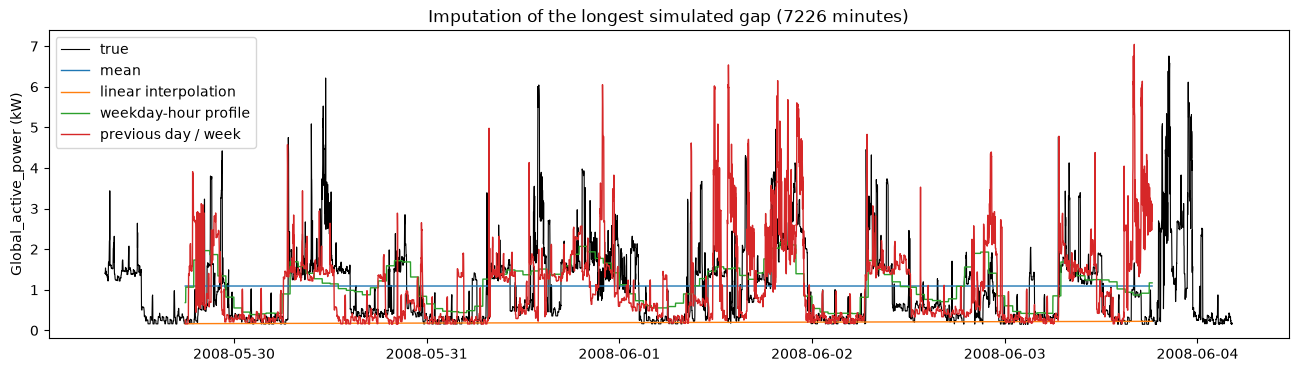

In [14]:
# Visual check on one simulated long gap
start, end = max(((g.index[0], g.index[-1]) for _, g in hid.groupby((hid != hid.shift()).cumsum()) if g.iloc[0]), key=lambda r: r[1] - r[0])
window = slice(start - 600, end + 600)
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(df_raw.index[window], df_raw.Global_active_power.iloc[window], color='black', lw=0.8, label='true')
for name in ['mean', 'linear interpolation', 'weekday-hour profile', 'previous day / week']:
    ax.plot(df_raw.index[start:end + 1], strategies[name](sim).Global_active_power.iloc[start:end + 1], lw=1, label=name)
ax.set_ylabel('Global_active_power (kW)')
ax.set_title(f'Imputation of the longest simulated gap ({end - start + 1} minutes)')
ax.legend()
plt.show()

1.25% of the minutes are missing in 71 gaps (median one minute, longest five days). The hybrid (linear interpolation up to 60 minutes, weekday-hour average beyond) is best with a normalised RMSE of 0.918, followed by the weekday-hour average (0.920) and the mean (0.973). Interpolation, forward fill and copying the previous day are worse on long gaps (1.14 to 1.21) but interpolation wins on short ones (0.32 against 0.81 for the mean). We keep the mean fill requested in the basic exercise, since it touches only 1.25% of the rows.

### Machine-Leaning: LSTM Data Preparation and feature engineering
We will apply recurrent nueral network (LSTM) which is best suited for time-seriers and sequential problem. This approach is the best if we have large data.  

We will frame the supervised learning problem as predicting the Global_active_power at the current time (t) given the Global_active_power measurement and other features at the prior time step.

In [15]:
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	dff = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(dff.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(dff.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg 

* In order to reduce the computation time, and also get a quick result to test the model.  One can resmaple the data over hour (the original data are given in minutes). This will reduce the size of data from 2075259 to 34589 but keep the overall strucure of data as shown in the above.   

In [16]:
## resampling of data over hour
df_resample = df.resample('h').mean() 
df_resample.shape

(34589, 7)

Note: Scale all features in range of [0,1]. 

Show 7 input variables (input series) and the 1 output variable for 'Global_active_power' at the current  time in hour (depending on resampling).

In [17]:
## If you would like to train based on the resampled data (over hour), then used below
values = df_resample.values 

# integer encode direction
# ensure all data is float
values = values.astype('float32')
# normalize features
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(values)
# frame as supervised learning
reframed = series_to_supervised(scaled, 1, 1)

# drop columns we don't want to predict
reframed.drop(reframed.columns[[8, 9, 10, 11, 12, 13]], axis=1, inplace=True)
print(reframed.head())

   var1(t-1)  var2(t-1)  var3(t-1)  var4(t-1)  var5(t-1)  var6(t-1)  \
1   0.636816   0.295738   0.337945   0.631157        0.0   0.011366   
2   0.545045   0.103358   0.335501   0.541487        0.0   0.144652   
3   0.509006   0.110073   0.283801   0.502152        0.0   0.030869   
4   0.488550   0.096987   0.315988   0.481110        0.0   0.000000   
5   0.455597   0.099010   0.434417   0.449904        0.0   0.008973   

   var7(t-1)   var1(t)  
1   0.782418  0.545045  
2   0.782676  0.509006  
3   0.774169  0.488550  
4   0.778809  0.455597  
5   0.798917  0.322555  


### Splitting the rest of data to train and validation sets

First, split the prepared dataset into train and test sets. To speed up the training of the model (for the sake of the demonstration), we will only train the model on the first year of data, then evaluate it on the next 3 years of data.

In [18]:
# split into train and test sets
values = reframed.values
n_train_time = 365*24
train = values[:n_train_time, :]
test = values[n_train_time:, :]
##test = values[n_train_time:n_test_time, :]
# split into input and outputs
train_X, train_y = train[:, :-1], train[:, -1]
test_X, test_y = test[:, :-1], test[:, -1]
# reshape input to be 3D [samples, timesteps, features]
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1]))
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape) 
# We reshaped the input into the 3D format as expected by 
# LSTMs, namely [samples, timesteps, features].

(8760, 1, 7) (8760,) (25828, 1, 7) (25828,)


#### Model architecture

1.  LSTM with 150 neurons in the first visible layer  
2. dropout 15%  
3. 1 neuron in the output layer for predicting Global_active_power.  
4. The input shape will be 1 time step with 7 features.  
5. Use the Mean Absolute Error (MAE) loss function and the efficient Adam version of stochastic gradient descent.  
6. The model will be fit for 30 training epochs with a batch size of 50.  

E0000 00:00:1791719723.822834 2349485 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/30


176/176 - 6s - 35ms/step - loss: 0.0886 - val_loss: 0.0681


Epoch 2/30


176/176 - 3s - 16ms/step - loss: 0.0723 - val_loss: 0.0633


...

176/176 - 3s - 14ms/step - loss: 0.0666 - val_loss: 0.0607


Epoch 29/30


176/176 - 2s - 14ms/step - loss: 0.0663 - val_loss: 0.0608


Epoch 30/30


176/176 - 3s - 18ms/step - loss: 0.0664 - val_loss: 0.0607


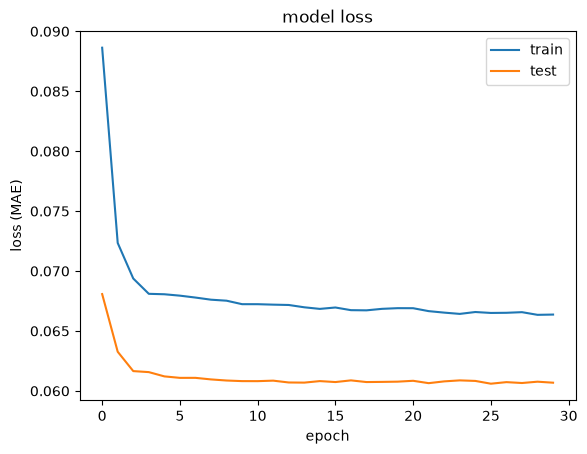

Test RMSE: 0.602


In [19]:
# here your code
def build_model():
    model = Sequential([keras.Input(shape=(train_X.shape[1], train_X.shape[2])),
                        LSTM(150),
                        Dropout(0.15),
                        Dense(1)])
    model.compile(loss='mae', optimizer='adam')
    return model

#    model.add(LSTM(70))
#    model.add(Dropout(0.3))

def invert_target(y_scaled, X):
    """Undo the [0,1] scaling of Global_active_power, which is column 0 of the scaler."""
    return scaler.inverse_transform(np.concatenate((y_scaled.reshape(-1, 1), X.reshape(len(X), -1)[:, 1:]), axis=1))[:, 0]

model = build_model()
# fit network
history = model.fit(train_X, train_y, epochs=30, batch_size=50, validation_data=(test_X, test_y), verbose=2, shuffle=False)

# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss (MAE)')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper right')
plt.show()

# make a prediction
yhat = model.predict(test_X, verbose=0)
# invert scaling for forecast
inv_yhat = invert_target(yhat, test_X)
# invert scaling for actual
inv_y = invert_target(test_y, test_X)
# calculate RMSE
rmse = np.sqrt(mean_squared_error(inv_y, inv_yhat))
print('Test RMSE: %.3f' % rmse)

Persistence RMSE: 0.656


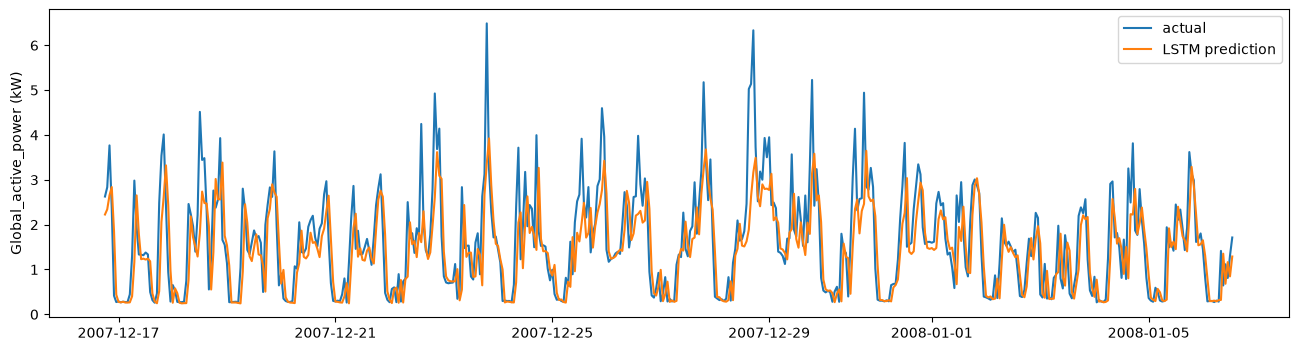

In [20]:
# Persistence baseline (predict the previous hour) for context, and a look at the first 500 test hours
inv_persist = invert_target(test_X[:, 0, 0], test_X)
print('Persistence RMSE: %.3f' % np.sqrt(mean_squared_error(inv_y, inv_persist)))

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(df_resample.index[n_train_time + 1:n_train_time + 501], inv_y[:500], label='actual')
ax.plot(df_resample.index[n_train_time + 1:n_train_time + 501], inv_yhat[:500], label='LSTM prediction')
ax.set_ylabel('Global_active_power (kW)')
ax.legend()
plt.show()

#### Advanced Exercise

To improve the model, one has to adjust epochs and batch_size. Find optimal values of the epoch and batch_size. 

In [21]:
# Your code here. 
# The test set must not be used for tuning: the training year is split again into
# 9 months for fitting and the last 3 months for validation (time order kept).
n_fit = 273 * 24
fit_X, fit_y = train_X[:n_fit], train_y[:n_fit]
val_X, val_y = train_X[n_fit:], train_y[n_fit:]

def val_rmse(model):
    return np.sqrt(mean_squared_error(invert_target(val_y, val_X), invert_target(model.predict(val_X, verbose=0), val_X)))

tuning = []
for batch_size in [8, 16, 32, 50, 64, 128, 256]:
    keras.utils.set_random_seed(19)
    model = build_model()
    stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(fit_X, fit_y, epochs=150, batch_size=batch_size, validation_data=(val_X, val_y),
                  callbacks=[stop], verbose=0, shuffle=False)
    tuning.append({'batch_size': batch_size,
                   'best_epochs': int(np.argmin(h.history['val_loss'])) + 1,
                   'val_RMSE': val_rmse(model),
                   'train_time_s': time.time() - t0,
                   'val_curve': h.history['val_loss']})
tuning_df = pd.DataFrame(tuning).set_index('batch_size')
tuning_df.drop(columns='val_curve').round(4)

,best_epochs,val_RMSE,train_time_s
batch_size,,,
8,8,0.7322,162.0971
16,16,0.7353,80.1076
32,27,0.7335,97.9025
50,26,0.7375,51.4540
64,24,0.7353,41.6940
128,32,0.7402,32.1742
256,97,0.7349,80.2797


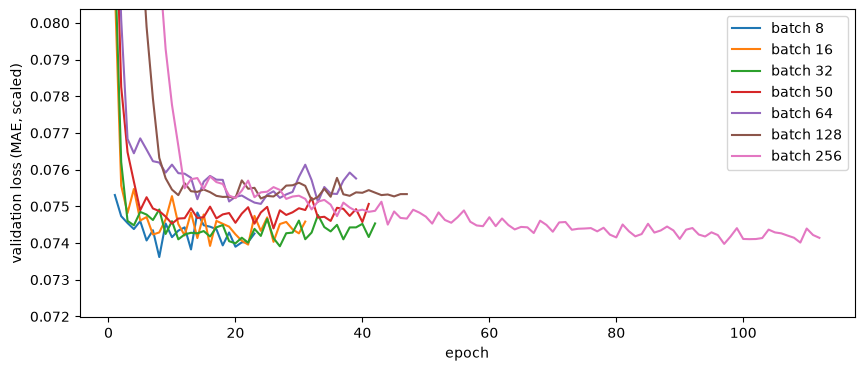

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
for bs, row in tuning_df.iterrows():
    ax.plot(np.arange(1, len(row.val_curve) + 1), row.val_curve, label=f'batch {bs}')
ax.set_xlabel('epoch')
ax.set_ylabel('validation loss (MAE, scaled)')
ax.set_ylim(top=np.quantile(np.concatenate(tuning_df.val_curve.values), 0.95))
ax.legend()
plt.show()

In [23]:
# Retrain on the full training year with the selected configuration and evaluate once on the test set
best_bs = tuning_df.val_RMSE.idxmin()
best_epochs = tuning_df.loc[best_bs, 'best_epochs']
keras.utils.set_random_seed(19)
tuned = build_model()
tuned.fit(train_X, train_y, epochs=best_epochs, batch_size=best_bs, verbose=0, shuffle=False)
tuned_rmse = np.sqrt(mean_squared_error(inv_y, invert_target(tuned.predict(test_X, verbose=0), test_X)))
print(f'Selected: batch_size={best_bs}, epochs={best_epochs}')
pd.Series({'baseline (30 epochs, batch 50)': rmse, f'tuned ({best_epochs} epochs, batch {best_bs})': tuned_rmse,
           'persistence': np.sqrt(mean_squared_error(inv_y, inv_persist))}, name='test RMSE (kW)').round(4)

Selected: batch_size=8, epochs=8


baseline (30 epochs, batch 50)    0.6019
tuned (8 epochs, batch 8)         0.5909
persistence                       0.6563
Name: test RMSE (kW), dtype: float64

Validation RMSE is 0.73 kW for every batch size from 8 to 256, a 1% spread that is within seed noise. Batch size mostly changes cost (8 epochs for batch 8, 97 for batch 256), and the validation loss is flat after about 10 epochs, so early stopping beats a fixed 30. Retraining with batch 8 and 8 epochs gives a test RMSE of 0.591 kW against 0.602 for the baseline and 0.656 for persistence, a gain too small to separate from noise.